# Análise exploratória: variáveis numéricas

**Notebook 02 de 04** · Entrada: `dados/diabetes_tratado.parquet` (gerado no notebook 01)


Este notebook analisa as **variáveis numéricas** (`IMC`, `DiasProblemasMentais` e `DiasProblemasFisicos`) da base *Diabetes Health Indicators* (BRFSS 2015), já tratada no notebook 01. O contexto da base e a tradução dos nomes das colunas estão no notebook 01, e o dicionário de variáveis completo está em `referencias/01_dicionario_de_dados.md`.

## Importações

Todas as importações do notebook ficam concentradas nesta célula. O `sys.path.append` permite importar o pacote `src` a partir da pasta `notebooks/`. O módulo `src.estatistica` traz as funções dos testes estatísticos e a `remove_outliers`, e o `src.config` traz os caminhos dos dados.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import (
    kstest,
    norm,
)

# Os notebooks ficam em notebooks/. Adicionamos a raiz do projeto ao caminho de
# importação para que o pacote `src` (config, estatistica, graficos) seja encontrado.
sys.path.append(str(Path.cwd().parent))

from src.config import DADOS_TRATADOS
from src.estatistica import (
    analise_levene,
    analise_mannwhitneyu,
    analise_ttest_ind,
    remove_outliers,
)


## Carregando a base tratada

Lê o arquivo `.parquet` gerado no notebook 01, que já mantém os tipos corretos (`category` e `int8`).

In [2]:
df_diabetes_tratado = pd.read_parquet(DADOS_TRATADOS)

df_diabetes_tratado.head()

,Diabetes,PressaoAlta,ColesterolAlto,ColesterolExame,IMC,Fumante,AVC,ProblemaCardiaco,AtividadeFisica,ComeFrutas,...,PlanoSaude,SemDinheiroConsultas,SaudeGeral,DiasProblemasMentais,DiasProblemasFisicos,DificuldadeAndar,Sexo,FaixaIdade,Ensino,FaixaRenda
0,Não,Sim,Não,Sim,26,Não,Não,Não,Sim,Não,...,Sim,Não,Boa,5,30,Não,Masculino,35 a 39 anos,Faculdade ou +,$75.000 ou mais
1,Não,Sim,Sim,Sim,26,Sim,Sim,Não,Não,Sim,...,Sim,Não,Boa,0,0,Não,Masculino,75 a 79 anos,Faculdade ou +,$75.000 ou mais
2,Não,Não,Não,Sim,26,Não,Não,Não,Sim,Sim,...,Sim,Não,Excelente,0,10,Não,Masculino,80 ou mais anos,Faculdade ou +,$75.000 ou mais
3,Não,Sim,Sim,Sim,28,Sim,Não,Não,Sim,Sim,...,Sim,Não,Boa,0,3,Não,Masculino,70 a 74 anos,Faculdade ou +,$75.000 ou mais
4,Não,Não,Não,Sim,29,Sim,Não,Não,Sim,Sim,...,Sim,Não,Muito Boa,0,0,Não,Feminino,55 a 59 anos,Faculdade incompleta ou Técnico,$75.000 ou mais


O `info()` confirma que os tipos foram preservados na leitura.

In [3]:
df_diabetes_tratado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Diabetes                70692 non-null  category
 1   PressaoAlta             70692 non-null  category
 2   ColesterolAlto          70692 non-null  category
 3   ColesterolExame         70692 non-null  category
 4   IMC                     70692 non-null  int8    
 5   Fumante                 70692 non-null  category
 6   AVC                     70692 non-null  category
 7   ProblemaCardiaco        70692 non-null  category
 8   AtividadeFisica         70692 non-null  category
 9   ComeFrutas              70692 non-null  category
 10  ComeLegumes             70692 non-null  category
 11  ConsumoBebidaAlcoolica  70692 non-null  category
 12  PlanoSaude              70692 non-null  category
 13  SemDinheiroConsultas    70692 non-null  category
 14  SaudeGeral            

## Separando as variáveis por tipo

Cria as listas de colunas reutilizadas nas análises: numéricas, variável alvo (`Diabetes`), categóricas, binárias (2 valores) e não binárias (as demais categóricas, que são ordinais).

In [4]:
# Listas de colunas por tipo, reutilizadas nas análises seguintes
colunas_numericas = df_diabetes_tratado.select_dtypes(include="number").columns.to_list()

coluna_alvo = "Diabetes"

colunas_categoricas = df_diabetes_tratado.select_dtypes(include="category").columns.to_list()
colunas_categoricas.remove(coluna_alvo)

colunas_binarias = df_diabetes_tratado.nunique()[df_diabetes_tratado.nunique() ==2].index.to_list()
colunas_binarias.remove(coluna_alvo)

# Lista (e não set) para manter a ordem original das colunas em todas as execuções
colunas_nao_binarias = [coluna for coluna in colunas_categoricas if coluna not in colunas_binarias]

Colunas numéricas:

In [5]:
colunas_numericas

['IMC', 'DiasProblemasMentais', 'DiasProblemasFisicos']

Variável alvo:

In [6]:
coluna_alvo

'Diabetes'

Colunas categóricas (exceto a variável alvo):

In [7]:
colunas_categoricas

['PressaoAlta',
 'ColesterolAlto',
 'ColesterolExame',
 'Fumante',
 'AVC',
 'ProblemaCardiaco',
 'AtividadeFisica',
 'ComeFrutas',
 'ComeLegumes',
 'ConsumoBebidaAlcoolica',
 'PlanoSaude',
 'SemDinheiroConsultas',
 'SaudeGeral',
 'DificuldadeAndar',
 'Sexo',
 'FaixaIdade',
 'Ensino',
 'FaixaRenda']

Colunas binárias (exceto a variável alvo):

In [8]:
colunas_binarias

['PressaoAlta',
 'ColesterolAlto',
 'ColesterolExame',
 'Fumante',
 'AVC',
 'ProblemaCardiaco',
 'AtividadeFisica',
 'ComeFrutas',
 'ComeLegumes',
 'ConsumoBebidaAlcoolica',
 'PlanoSaude',
 'SemDinheiroConsultas',
 'DificuldadeAndar',
 'Sexo']

Colunas não binárias, que são as categóricas ordinais:

In [9]:
colunas_nao_binarias

['SaudeGeral', 'FaixaIdade', 'Ensino', 'FaixaRenda']

Quantidade de colunas em cada lista, ordenada da menor para a maior. O resultado fecha: 14 binárias + 4 não binárias = 18 categóricas.

In [10]:
# Criamos pares de (nome, lista)
todas_colunas = [
    ("colunas_numericas", colunas_numericas),
    ("colunas_categoricas", colunas_categoricas),
    ("colunas_binarias", colunas_binarias),
    ("colunas_nao_binarias", colunas_nao_binarias)
]

# Ordena pelo tamanho da lista (item 1 da tupla)
ordenadas_com_nome = sorted(todas_colunas, key=lambda item: len(item[1]))

# Exibe o nome e a quantidade de menor para maior
for nome, lista in ordenadas_com_nome:
    print(f"{nome}: {len(lista)} colunas")

colunas_numericas: 3 colunas
colunas_nao_binarias: 4 colunas
colunas_binarias: 14 colunas
colunas_categoricas: 18 colunas


## Variáveis numéricas

Boxplots das variáveis numéricas separados por `Diabetes`, para comparar mediana, dispersão e outliers entre os grupos.

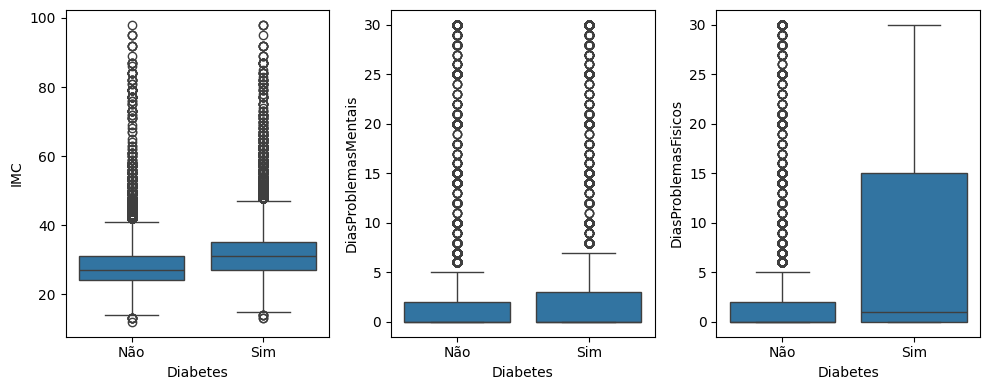

In [11]:
# Um boxplot por variável numérica, separado por grupo (Diabetes Não/Sim)
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

for ax, coluna in zip(axs, colunas_numericas):
    sns.boxplot(data=df_diabetes_tratado, x=coluna_alvo, y=coluna, ax=ax)

plt.tight_layout()
plt.show()

Histogramas com curva KDE (`kde=True`), com uma cor por grupo, para observar a forma de cada distribuição.

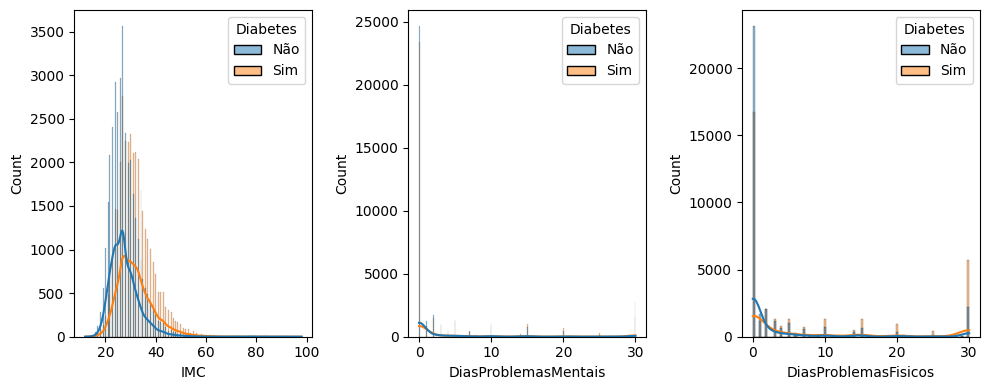

In [12]:
# Um histograma com KDE por variável numérica, uma cor por grupo
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

for ax, coluna in zip(axs, colunas_numericas):
    sns.histplot(data=df_diabetes_tratado, x=coluna, hue=coluna_alvo, kde=True, ax=ax)

plt.tight_layout()
plt.show()

Estatísticas descritivas de cada variável numérica, separadas por grupo (`Diabetes` Não/Sim).

In [13]:
df_diabetes_tratado.groupby(coluna_alvo, observed=True).describe().T

Diabetes                             Não           Sim
IMC                  count  35346.000000  35346.000000
                     mean      27.769960     31.944011
                     std        6.187636      7.363401
                     min       12.000000     13.000000
                     25%       24.000000     27.000000
                     50%       27.000000     31.000000
                     75%       31.000000     35.000000
                     max       98.000000     98.000000
DiasProblemasMentais count  35346.000000  35346.000000
                     mean       3.042268      4.461806
                     std        7.208408      8.947717
                     min        0.000000      0.000000
                     25%        0.000000      0.000000
                     50%        0.000000      0.000000
                     75%        2.000000      3.000000
                     max       30.000000     30.000000
DiasProblemasFisicos count  35346.000000  35346.000000
                     mean       3.666355      7.954479
                     std        8.098339     11.301491
                     min        0.000000      0.000000
                     25%        0.000000      0.000000
                     50%        0.000000      1.000000
                     75%        2.000000     15.000000
                     max       30.000000     30.000000

O `IMC` médio é maior no grupo com diabetes (cerca de 31,9 contra 27,8 no grupo sem diabetes).

Matriz de correlação (Pearson) entre as variáveis numéricas.

In [14]:
df_diabetes_tratado.corr(numeric_only=True)

,IMC,DiasProblemasMentais,DiasProblemasFisicos
IMC,1.000000,0.104682,0.161862
DiasProblemasMentais,0.104682,1.000000,0.380272
DiasProblemasFisicos,0.161862,0.380272,1.000000


As correlações entre as variáveis numéricas são fracas a moderadas. A maior delas é entre `DiasProblemasMentais` e `DiasProblemasFisicos` (cerca de 0,38).

## Faz sentido testar a normalidade das variáveis numéricas?

Assimetria (*skewness*) por grupo. Valores positivos indicam cauda mais longa à direita.

In [15]:
df_diabetes_tratado.groupby(coluna_alvo, observed=False).skew(numeric_only=True)

,IMC,DiasProblemasMentais,DiasProblemasFisicos
Diabetes,,,
Não,2.231015,2.808070,2.480202
Sim,1.527018,2.065169,1.150047


Todos os valores são positivos: as distribuições são assimétricas à direita.

Curtose (*kurtosis*) por grupo. O pandas calcula a curtose em excesso, em que 0 corresponde à de uma distribuição normal.

In [16]:
df_diabetes_tratado.groupby(coluna_alvo, observed=True)[colunas_numericas].apply(pd.DataFrame.kurtosis)

,IMC,DiasProblemasMentais,DiasProblemasFisicos
Diabetes,,,
Não,12.901012,7.012218,4.910598
Sim,5.717382,2.873176,-0.341922


No grupo sem diabetes, o `IMC` tem curtose alta (cerca de 12,9), o que indica caudas pesadas, coerente com os valores extremos vistos nos boxplots.

Separa os valores de `IMC` de cada grupo em arrays, para usar nos testes estatísticos.

In [17]:
# Valores de IMC de cada grupo, em arrays, para os testes estatísticos
dados_imc_sim = df_diabetes_tratado.query("Diabetes == 'Sim'")["IMC"].values
dados_imc_nao = df_diabetes_tratado.query("Diabetes == 'Não'")["IMC"].values

Teste de Kolmogorov-Smirnov comparando o `IMC` de cada grupo com uma normal de mesma média e desvio padrão.

In [18]:
# KS compara a distribuição observada com uma normal de mesma média e desvio padrão.
# H0: os dados seguem a distribuição normal
print(kstest(dados_imc_nao, norm.cdf, args=(dados_imc_nao.mean(), dados_imc_nao.std())))
print(kstest(dados_imc_sim, norm.cdf, args=(dados_imc_sim.mean(), dados_imc_sim.std())))

KstestResult(statistic=np.float64(0.1209153634702329), pvalue=np.float64(0.0), statistic_location=np.int8(28), statistic_sign=np.int8(1))
KstestResult(statistic=np.float64(0.10452803408478695), pvalue=np.float64(0.0), statistic_location=np.int8(33), statistic_sign=np.int8(1))


Em ambos os grupos o p-valor é praticamente 0, então a hipótese de normalidade é rejeitada. Com amostras tão grandes (cerca de 35 mil registros por grupo), o teste rejeita até desvios pequenos. Por isso olhamos também assimetria, curtose e gráficos antes de decidir.

Monta um DataFrame com uma coluna de `IMC` para cada grupo, formato esperado pelas funções de teste de `src/estatistica.py`.

In [19]:
# Uma coluna por grupo: formato esperado pelas funções de src/estatistica.py
df_imc = pd.DataFrame({"Sim": dados_imc_sim, "Não": dados_imc_nao})

df_imc

,Sim,Não
0,30,26
1,25,26
2,28,26
3,23,28
4,27,29
...,...,...
35341,37,23
35342,29,29
35343,25,24
35344,18,53


Teste de Levene para verificar se as variâncias dos dois grupos são iguais (usando a mediana como centro).

In [20]:
analise_levene(df_imc, centro="median")

Teste de Levene
estatistica_levene=888.297
Ao menos uma variância é diferente (valor p: 0.000)


p-valor próximo de 0: as variâncias dos grupos são diferentes. É por isso que o teste t a seguir assume variâncias diferentes.

Teste t para amostras independentes, assumindo variâncias diferentes entre os grupos.

In [21]:
analise_ttest_ind(df_imc, variancias_iguais=False)

Teste t de Student
estatistica_ttest=81.591
Rejeita a hipótese nula (valor p: 0.000)


Rejeita a hipótese nula: a média de `IMC` difere entre os grupos.

Teste de Mann-Whitney, alternativa não paramétrica que não exige normalidade dos dados.

In [22]:
analise_mannwhitneyu(df_imc)

Teste de Mann-Whitney
estatistica_mw=861173484.000
Rejeita a hipótese nula (valor p: 0.000)


Também rejeita a hipótese nula, confirmando o resultado do teste t sem depender da normalidade.

## Os outliers interferem nos testes de normalidade?

Aplica a função `remove_outliers` (importada de `src/estatistica.py`) em cada variável numérica. Os valores fora dos limites do boxplot viram `NaN`.

In [23]:
# remove_outliers mantém só os valores dentro dos limites do boxplot (1,5 x IQR).
# Ao atribuir de volta, os valores removidos viram NaN (alinhamento pelo índice)
df_diabetes_tratado_sem_outliers = df_diabetes_tratado.copy()

for coluna in colunas_numericas:
    df_diabetes_tratado_sem_outliers[coluna] = remove_outliers(df_diabetes_tratado[coluna])

df_diabetes_tratado_sem_outliers.describe()

,IMC,DiasProblemasMentais,DiasProblemasFisicos
count,68511.000000,58876.000000,60068.000000
mean,29.129673,0.526615,1.880619
std,5.695466,1.271375,3.727202
min,13.000000,0.000000,0.000000
25%,25.000000,0.000000,0.000000
50%,28.000000,0.000000,0.000000
75%,33.000000,0.000000,2.000000
max,45.000000,5.000000,15.000000


O limite do boxplot elimina muitos registros de `DiasProblemasMentais` e `DiasProblemasFisicos`: como a maior parte dos valores é 0, o intervalo interquartil é pequeno e muitos registros são classificados como outliers. No `IMC`, o máximo cai de 98 para 45.

O `info()` mostra o efeito da remoção: as colunas numéricas passam a ter valores nulos (o `IMC`, por exemplo, fica com 68.511 valores válidos de 70.692).

In [24]:
df_diabetes_tratado_sem_outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Diabetes                70692 non-null  category
 1   PressaoAlta             70692 non-null  category
 2   ColesterolAlto          70692 non-null  category
 3   ColesterolExame         70692 non-null  category
 4   IMC                     68511 non-null  float64 
 5   Fumante                 70692 non-null  category
 6   AVC                     70692 non-null  category
 7   ProblemaCardiaco        70692 non-null  category
 8   AtividadeFisica         70692 non-null  category
 9   ComeFrutas              70692 non-null  category
 10  ComeLegumes             70692 non-null  category
 11  ConsumoBebidaAlcoolica  70692 non-null  category
 12  PlanoSaude              70692 non-null  category
 13  SemDinheiroConsultas    70692 non-null  category
 14  SaudeGeral            

Boxplots após a remoção dos outliers.

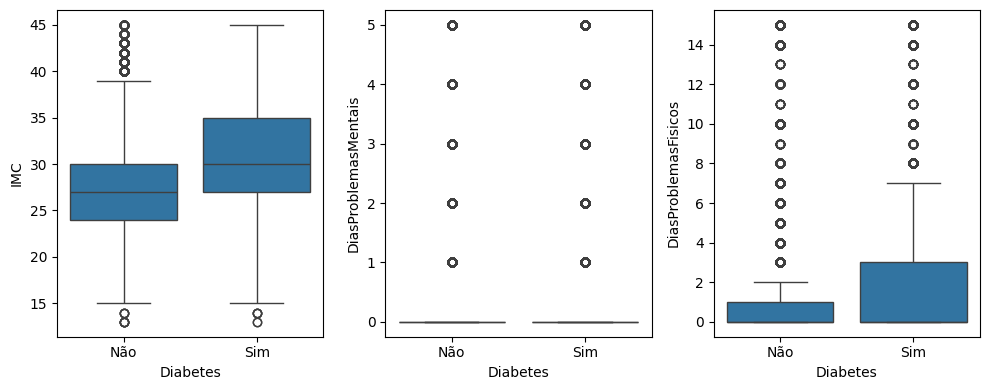

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

for ax, coluna in zip(axs, colunas_numericas):
    sns.boxplot(data=df_diabetes_tratado_sem_outliers, x=coluna_alvo, y=coluna, ax=ax)

plt.tight_layout()
plt.show()

Histogramas após a remoção dos outliers.

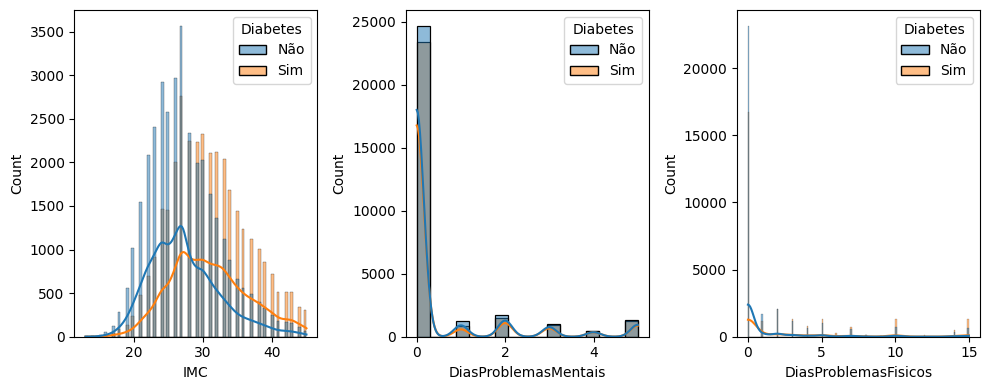

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

for ax, coluna in zip(axs, colunas_numericas):
    sns.histplot(data=df_diabetes_tratado_sem_outliers, x=coluna, hue=coluna_alvo, kde=True, ax=ax)

plt.tight_layout()
plt.show()

Assimetria por grupo, sem outliers.

In [27]:
df_diabetes_tratado_sem_outliers.groupby(coluna_alvo, observed=True).skew(numeric_only=True)

,IMC,DiasProblemasMentais,DiasProblemasFisicos
Diabetes,,,
Não,0.714415,2.454599,2.874805
Sim,0.323244,2.507093,1.856026


A assimetria do `IMC` diminui nos dois grupos em relação à análise com outliers.

Curtose por grupo, sem outliers.

In [28]:
df_diabetes_tratado_sem_outliers.groupby(coluna_alvo, observed=True)[colunas_numericas].apply(pd.DataFrame.kurtosis)

,IMC,DiasProblemasMentais,DiasProblemasFisicos
Diabetes,,,
Não,0.481335,5.003764,8.079214
Sim,-0.343434,5.185706,2.367289


A curtose do `IMC` no grupo sem diabetes cai de cerca de 12,9 para 0,48: as caudas pesadas vinham dos valores extremos.

Separa novamente o `IMC` de cada grupo, agora sem outliers.

In [29]:
dados_imc_sim_sem_outliers = df_diabetes_tratado_sem_outliers.query("Diabetes == 'Sim'")["IMC"].values
dados_imc_nao_sem_outliers = df_diabetes_tratado_sem_outliers.query("Diabetes == 'Não'")["IMC"].values

DataFrame com os dois grupos lado a lado. Como cada grupo perdeu uma quantidade diferente de registros, aparecem valores `NaN`.

In [30]:
df_imc_sem_outliers = pd.DataFrame({"Sim": dados_imc_sim_sem_outliers, "Não": dados_imc_nao_sem_outliers})

df_imc_sem_outliers

,Sim,Não
0,30.0,26.0
1,25.0,26.0
2,28.0,26.0
3,23.0,28.0
4,27.0,29.0
...,...,...
35341,37.0,23.0
35342,29.0,29.0
35343,25.0,24.0
35344,18.0,NaN


Teste de Kolmogorov-Smirnov novamente, com `nan_policy='omit'` para ignorar os valores nulos.

In [31]:
# nan_policy='omit' ignora os NaN deixados pela remoção dos outliers
print(
    kstest(
        df_imc_sem_outliers["Não"], 
        norm.cdf, 
        args=(df_imc_sem_outliers["Não"].mean(), 
              df_imc_sem_outliers["Não"].std()), 
              nan_policy='omit')
)
print(
    kstest(
        df_imc_sem_outliers["Sim"], 
        norm.cdf, 
        args=(df_imc_sem_outliers["Sim"].mean(), 
              df_imc_sem_outliers["Sim"].std()), 
              nan_policy='omit')
    )

KstestResult(statistic=np.float64(0.10815079726309113), pvalue=np.float64(0.0), statistic_location=np.float64(27.0), statistic_sign=np.int8(1))
KstestResult(statistic=np.float64(0.07345716240963451), pvalue=np.float64(2.337007202521087e-158), statistic_location=np.float64(30.0), statistic_sign=np.int8(1))


O p-valor continua praticamente 0 nos dois grupos, então a normalidade segue rejeitada. Porém a estatística KS diminuiu em ambos (de cerca de 0,121 para 0,108 no grupo "Não" e de 0,105 para 0,073 no grupo "Sim"), mostrando que os outliers influenciavam o ajuste.

Teste de Levene sem outliers.

In [32]:
analise_levene(df_imc_sem_outliers, centro="median")

Teste de Levene
estatistica_levene=532.986
Ao menos uma variância é diferente (valor p: 0.000)


Teste t sem outliers.

In [33]:
analise_ttest_ind(df_imc_sem_outliers, variancias_iguais=False)

Teste t de Student
estatistica_ttest=85.248
Rejeita a hipótese nula (valor p: 0.000)


Teste de Mann-Whitney sem outliers.

In [34]:
analise_mannwhitneyu(df_imc_sem_outliers)

Teste de Mann-Whitney
estatistica_mw=801702843.000
Rejeita a hipótese nula (valor p: 0.000)


Mesmo sem outliers, os três testes (Levene, t e Mann-Whitney) chegam à mesma conclusão: os grupos diferem em `IMC`.